# Лабораторная работа №2. Методы классификации и нейронные сети
### Отчет по практическому заданию курса «Машинное обучение»

### 1) Введение. Краткое описание целей и задач работы

- **Цель работы:** изучить методы классификации из библиотеки scikit-learn и построить нейронную сеть на TensorFlow, сравнив качество моделей и влияние гиперпараметров.
- **Постановка задачи:**
  1. Выбрать и подготовить датасет для бинарной классификации.
  2. Обучить наивный байесовский классификатор в вариантах GaussianNB, MultinomialNB, ComplementNB и BernoulliNB.
  3. Обучить дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод k ближайших соседей.
  4. Сравнить модели по Accuracy, Precision, Recall, F1-score и AUC-ROC.
  5. Подобрать гиперпараметры и показать, как они меняют качество.
  6. Построить нейронную сеть на TensorFlow, записать ход обучения в TensorBoard и посмотреть, как число эпох, размер батча, глубина и функция активации меняют качество.
- **Датасет:** Pima Indians Diabetes Database с Kaggle. Наблюдение — одна пациентка. Целевая переменная — диабет: 0 нет, 1 есть.


In [1]:
from pathlib import Path
import os
import urllib.request

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
TB_DIR = OUTPUT_DIR / "tensorboard"
DATA_PATH = DATA_DIR / "diabetes.csv"
DATA_URL = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]
TARGET = "Outcome"
MISSING_AS_ZERO = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
LABELS = {
    "Pregnancies": "Беременности",
    "Glucose": "Глюкоза",
    "BloodPressure": "Давление",
    "SkinThickness": "Толщина кожи",
    "Insulin": "Инсулин",
    "BMI": "Индекс массы тела",
    "DiabetesPedigreeFunction": "Родословная",
    "Age": "Возраст",
    "Outcome": "Диабет",
}


class MedianBinarizer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.threshold_ = np.nanmedian(np.asarray(X, dtype=float), axis=0)
        return self

    def transform(self, X):
        values = np.asarray(X, dtype=float)
        return (values > self.threshold_).astype(float)


np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TB_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
if not DATA_PATH.exists() or DATA_PATH.stat().st_size == 0:
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw = pd.read_csv(DATA_PATH)
display(raw.head())
zero_missing = pd.Series({column: int((raw[column] == 0).sum()) for column in MISSING_AS_ZERO}, name="нули как пропуск")
display(zero_missing.to_frame())
class_counts = raw[TARGET].value_counts().sort_index().rename({0: "нет диабета", 1: "диабет"})
display(class_counts.to_frame("число наблюдений"))


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,нули как пропуск
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


,число наблюдений
Outcome,
нет диабета,500
диабет,268


### Пояснение к датасету

- **Источник:** Pima Indians Diabetes Database, публикация на Kaggle: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database. Файл сохранён в `data/diabetes.csv`.
- **Объём:** в таблице **768** наблюдений и **8** признаков. Явных пропусков в файле нет, но нули в части измерений физиологически невозможны и дальше считаются пропусками: Глюкоза — 5, Давление — 35, Толщина кожи — 227, Инсулин — 374, Индекс массы тела — 11.
- **Признаки:** число беременностей, глюкоза, диастолическое давление, толщина кожной складки, инсулин, индекс массы тела, функция родословной по диабету и возраст.
- **Классы:** без диабета **500** наблюдений, с диабетом **268**. Положительный класс для Precision и Recall — наличие диабета.
- **Почему набор подходит байесовским моделям:** после замены нулей медианой все признаки неотрицательные. MultinomialNB и ComplementNB получают исходные значения, BernoulliNB — индикатор «выше медианы», GaussianNB — стандартизованные значения.


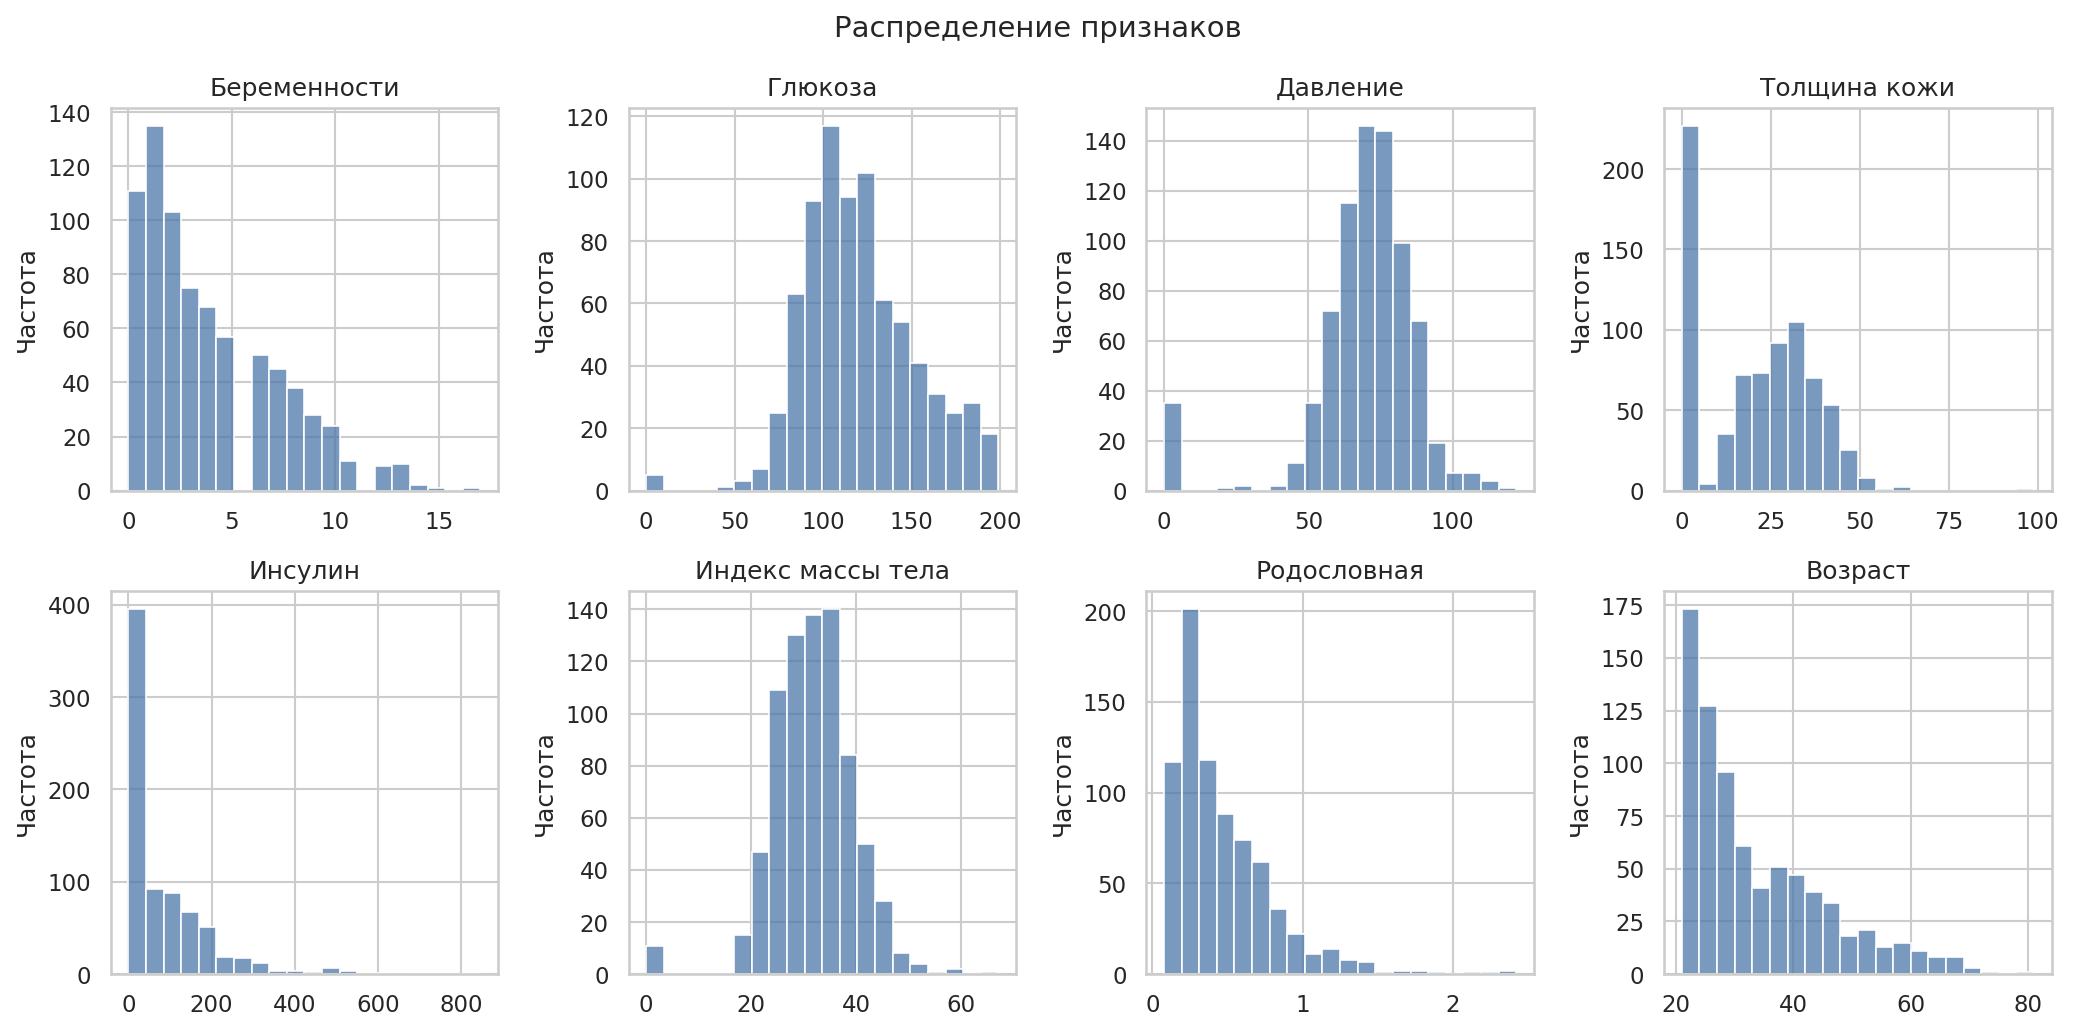

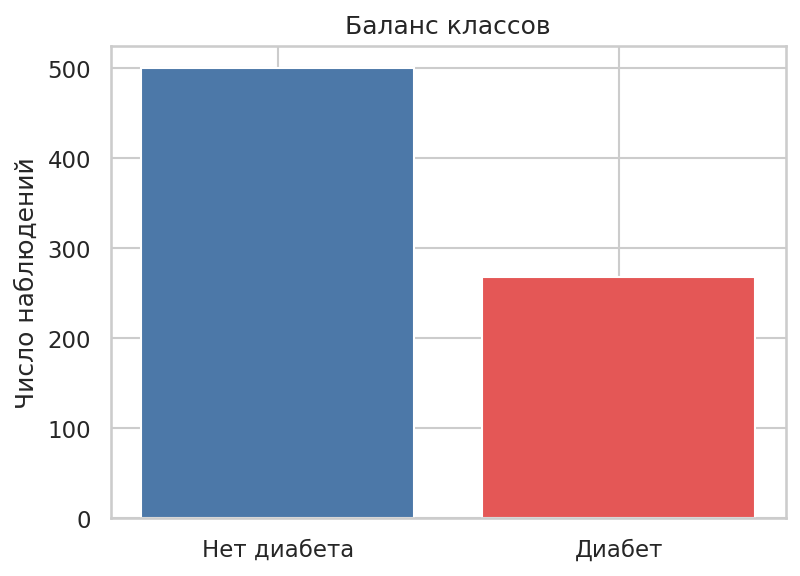

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, column in zip(axes.ravel(), FEATURES):
    sns.histplot(raw[column], bins=20, ax=ax, color="#4C78A8")
    ax.set_title(LABELS[column])
    ax.set_xlabel("")
    ax.set_ylabel("Частота")
fig.suptitle("Распределение признаков", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_distributions.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4))
counts = raw[TARGET].value_counts().sort_index()
ax.bar(["Нет диабета", "Диабет"], counts.values, color=["#4C78A8", "#E45756"])
ax.set_ylabel("Число наблюдений")
ax.set_title("Баланс классов")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_class_balance.png", bbox_inches="tight")
plt.show()


### Пояснение к распределениям

- Признаки непрерывные, шкалы разные: возраст и глюкоза измеряются десятками, родословная — долями, инсулин — сотнями. Столбец на нуле у инсулина и толщины кожи — это нетипично частый ноль, то есть пропущенное измерение, а не реальное значение.
- Классы несбалансированы: диабет есть у 0,349 доли выборки. Одной Accuracy недостаточно, дальше смотрим ещё Precision, Recall, F1 и AUC-ROC.
- Число беременностей может быть нулём по смыслу, поэтому этот ноль пропуском не считается.


Обучающая выборка: 614
Тестовая выборка: 154
Доля диабета в тесте: 0.351


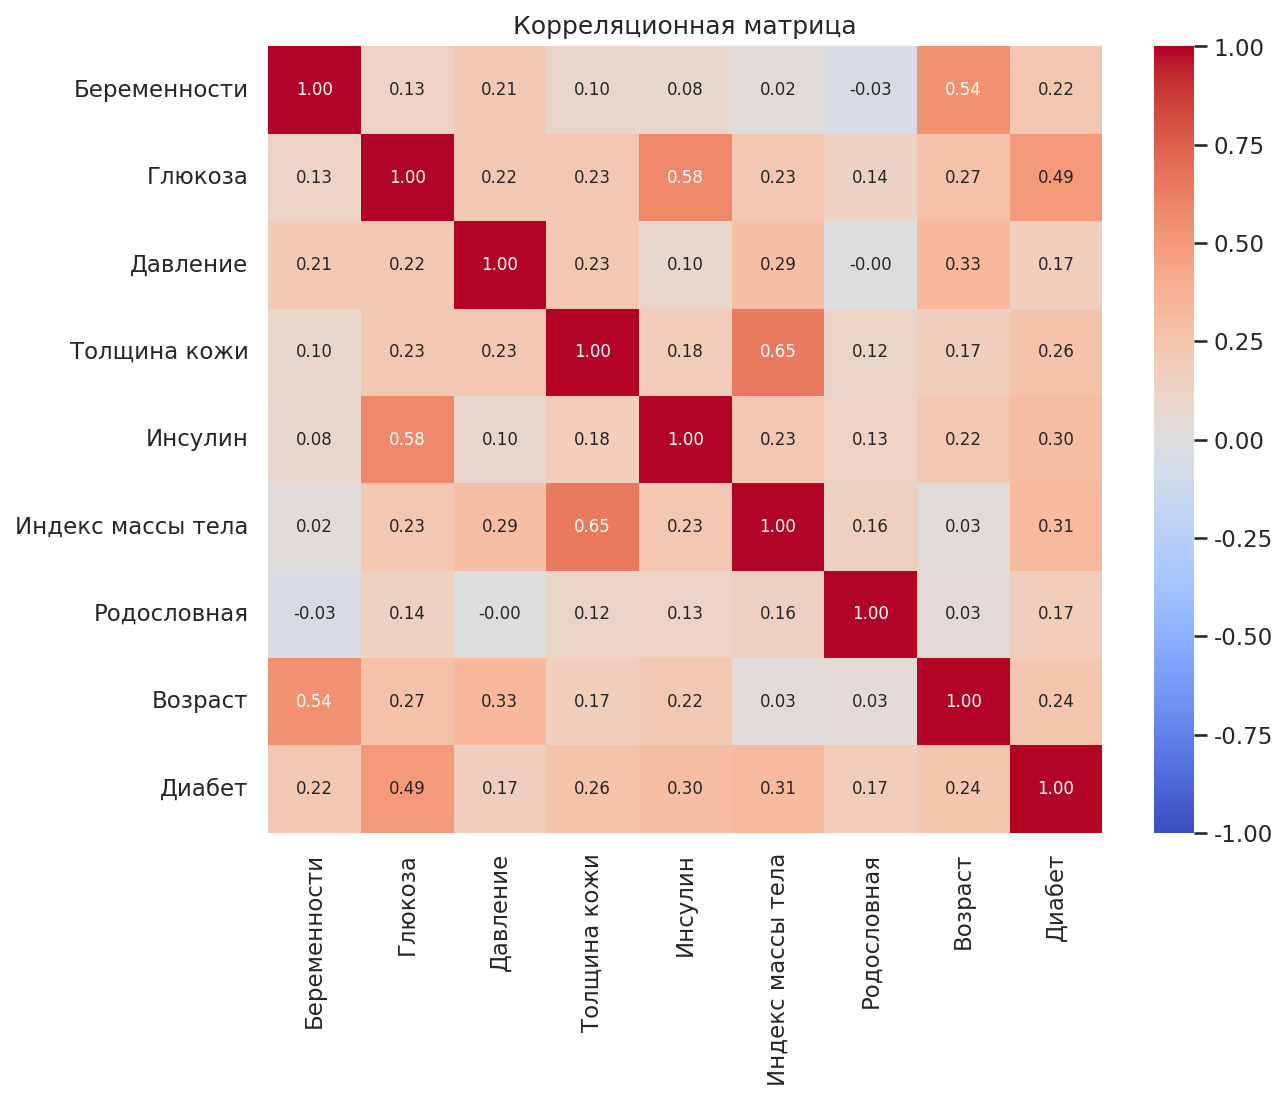

,медиана обучающей выборки
Беременности,3.000
Глюкоза,117.000
Давление,72.000
Толщина кожи,29.000
Инсулин,125.000
Индекс массы тела,32.400
Родословная,0.382
Возраст,29.000


In [4]:
clean = raw.copy()
for column in MISSING_AS_ZERO:
    clean.loc[clean[column] == 0, column] = np.nan

corr = clean[FEATURES + [TARGET]].corr()
corr.rename(index=LABELS, columns=LABELS).to_csv(OUTPUT_DIR / "correlation.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    corr.rename(index=LABELS, columns=LABELS),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    annot_kws={"size": 8},
)
ax.set_title("Корреляционная матрица")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_correlation.png", bbox_inches="tight")
plt.show()

x = clean[FEATURES]
y = clean[TARGET].astype(int)
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
medians = x_train.median()
x_train = x_train.fillna(medians)
x_test = x_test.fillna(medians)
display(medians.rename(LABELS).round(3).to_frame("медиана обучающей выборки"))

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print(f"Обучающая выборка: {len(x_train)}")
print(f"Тестовая выборка: {len(x_test)}")
print(f"Доля диабета в тесте: {y_test.mean():.3f}")


### Пояснение к подготовке и разбиению

- Нули в глюкозе, давлении, толщине кожи, инсулине и индексе массы тела заменены на пропуск. Медианы посчитаны только по обучающей части и подставлены в обе выборки, чтобы тестовые значения не влияли на заполнение.
- С диагнозом сильнее всего связан признак «Глюкоза»: корреляция 0,49. Остальные связи слабее, но глюкоза, масса тела и возраст обычно тянутся в одну сторону с риском диабета.
- Выборка разделена стратифицированно 80/20 (`random_state = 42`): **614** наблюдений на обучение и **154** на тест. Доля диабета в тесте — 0,351.
- Подбор параметров идёт только по обучающей части, 5-кратной стратифицированной кросс-валидацией. Тест используется один раз для итоговых метрик.


In [5]:
def positive_score(model, x_values):
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(x_values)
        if getattr(proba, "ndim", 1) == 2 and proba.shape[1] == 2:
            return np.asarray(proba[:, 1], dtype=float)
    if hasattr(model, "decision_function"):
        return np.asarray(model.decision_function(x_values), dtype=float).ravel()
    return np.asarray(model.predict(x_values), dtype=float).ravel()


def classification_metrics(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AUC_ROC": roc_auc_score(y_true, y_score),
    }


def evaluate_model(name, model, x_values, y_values):
    prediction = model.predict(x_values)
    score = positive_score(model, x_values)
    row = {"Модель": name, **classification_metrics(y_values, prediction, score)}
    return row, score


results = []
test_scores = {}


,Accuracy,Precision,Recall,F1,AUC_ROC,Параметр,CV F1
Модель,,,,,,,
GaussianNB,0.701,0.567,0.630,0.596,0.765,model__var_smoothing=1e-12,0.637
MultinomialNB,0.623,0.447,0.315,0.370,0.615,alpha=0.01,0.433
ComplementNB,0.636,0.481,0.463,0.472,0.615,alpha=0.01,0.437
BernoulliNB,0.727,0.630,0.537,0.580,0.759,model__alpha=5.0,0.597


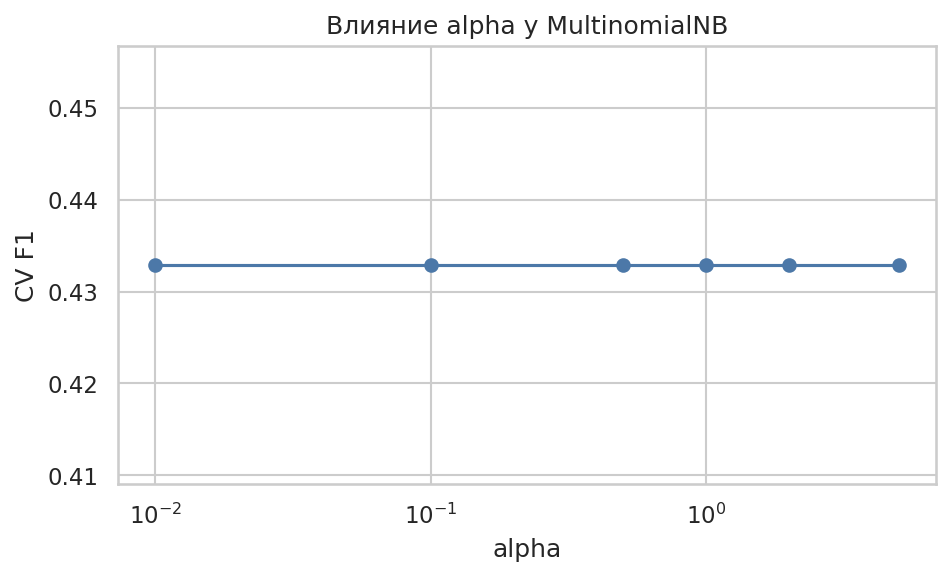

In [6]:
bayes_specs = {
    "GaussianNB": (
        Pipeline([("scaler", StandardScaler()), ("model", GaussianNB())]),
        {"model__var_smoothing": np.logspace(-12, -2, 6)},
    ),
    "MultinomialNB": (
        MultinomialNB(),
        {"alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]},
    ),
    "ComplementNB": (
        ComplementNB(),
        {"alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]},
    ),
    "BernoulliNB": (
        Pipeline([("bin", MedianBinarizer()), ("model", BernoulliNB())]),
        {"model__alpha": [0.1, 1.0, 5.0]},
    ),
}

bayes_rows = []
for name, (estimator, grid) in bayes_specs.items():
    search = GridSearchCV(estimator, grid, scoring="f1", cv=cv, n_jobs=1)
    search.fit(x_train, y_train)
    row, score = evaluate_model(name, search.best_estimator_, x_test, y_test)
    row["Параметр"] = ", ".join(f"{key}={value}" for key, value in search.best_params_.items())
    row["CV F1"] = float(search.best_score_)
    bayes_rows.append(row)
    results.append({key: value for key, value in row.items() if key != "Параметр"})
    test_scores[name] = score

bayes_table = pd.DataFrame(bayes_rows).set_index("Модель")
bayes_table.to_csv(OUTPUT_DIR / "metrics_bayes.csv", encoding="utf-8-sig")
display(bayes_table.round(3))

alpha_grid = np.array([0.01, 0.1, 0.5, 1.0, 2.0, 5.0])
alpha_scores = []
for alpha in alpha_grid:
    search = GridSearchCV(MultinomialNB(), {"alpha": [alpha]}, scoring="f1", cv=cv)
    search.fit(x_train, y_train)
    alpha_scores.append(search.best_score_)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(alpha_grid, alpha_scores, marker="o", color="#4C78A8")
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("CV F1")
ax.set_title("Влияние alpha у MultinomialNB")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_nb_alpha.png", bbox_inches="tight")
plt.show()


### Пояснение к наивному байесовскому классификатору

- **Идея метода.** Признак считается условно независимым при известном классе. Для непрерывных измерений это GaussianNB, для неотрицательных величин — MultinomialNB и ComplementNB, для бинарных индикаторов — BernoulliNB.
- **Настройка.** У GaussianNB перебирался `var_smoothing`, у MultinomialNB и ComplementNB — сглаживание `alpha`, у BernoulliNB — `alpha` после бинаризации каждого признака по его медиане. Критерий выбора — средний F1 на кросс-валидации.
- **Результат на тесте.** Лучший из четырёх вариантов — **GaussianNB**: Accuracy = 0,701, Precision = 0,567, Recall = 0,630, F1 = 0,596, AUC-ROC = 0,765.
- **Влияние alpha.** На графике F1 MultinomialNB почти не меняется: сглаживание не перестраивает решающее правило. MultinomialNB здесь слабее по смыслу: инсулин и глюкоза имеют разный масштаб и не являются частотами, поэтому большая величина перетягивает правдоподобие.


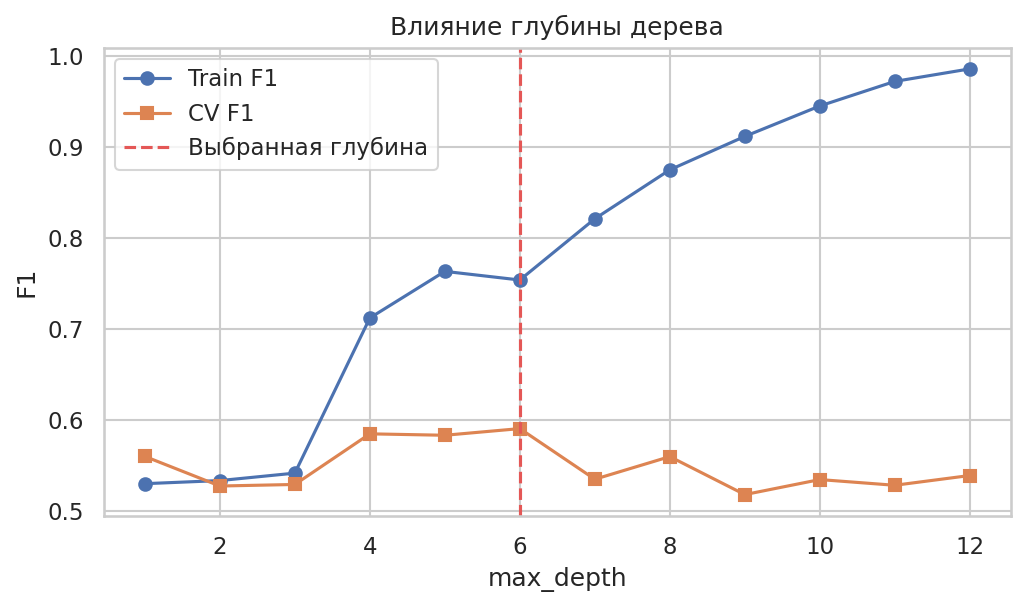

,Accuracy,Precision,Recall,F1,AUC_ROC,Параметр
Модель,,,,,,
Decision Tree,0.74,0.675,0.5,0.574,0.811,"max_depth=6, min_samples_leaf=10"


,важность
Глюкоза,0.579
Индекс массы тела,0.183
Возраст,0.112
Родословная,0.046
Давление,0.038
Беременности,0.032
Инсулин,0.012
Толщина кожи,0.000


In [7]:
depth_rows = []
for depth in range(1, 13):
    search = GridSearchCV(
        DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE),
        {"min_samples_leaf": [1]},
        scoring="f1",
        cv=cv,
    )
    search.fit(x_train, y_train)
    train_pred = search.predict(x_train)
    depth_rows.append(
        {
            "max_depth": depth,
            "CV F1": search.best_score_,
            "Train F1": f1_score(y_train, train_pred),
        }
    )
depth_table = pd.DataFrame(depth_rows)

tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {"max_depth": list(range(1, 13)), "min_samples_leaf": [1, 5, 10]},
    scoring="f1",
    cv=cv,
)
tree_search.fit(x_train, y_train)
tree_row, tree_score = evaluate_model("Decision Tree", tree_search.best_estimator_, x_test, y_test)
tree_row["Параметр"] = ", ".join(f"{key}={value}" for key, value in tree_search.best_params_.items())
results.append({key: value for key, value in tree_row.items() if key != "Параметр"})
test_scores["Decision Tree"] = tree_score

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(depth_table["max_depth"], depth_table["Train F1"], marker="o", label="Train F1")
ax.plot(depth_table["max_depth"], depth_table["CV F1"], marker="s", label="CV F1")
ax.axvline(tree_search.best_params_["max_depth"], color="#E45756", linestyle="--", label="Выбранная глубина")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1")
ax.set_title("Влияние глубины дерева")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_tree_depth.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame([tree_row]).set_index("Модель").round(3))
importances = pd.Series(
    tree_search.best_estimator_.feature_importances_, index=[LABELS[name] for name in FEATURES]
).sort_values(ascending=False)
display(importances.round(3).to_frame("важность"))


### Пояснение к дереву решений

- **Идея метода.** Дерево последовательно делит пациенток по порогам признаков. Глубина и минимальное число объектов в листе ограничивают дробление выборки.
- **Настройка.** Перебраны `max_depth` от 1 до 12 и `min_samples_leaf` из множества 1, 5 и 10. На графике train F1 растёт вместе с глубиной, а CV F1 отстаёт: глубокое дерево запоминает обучающие строки.
- **Выбранные параметры:** max_depth=6, min_samples_leaf=10. На тесте Accuracy = 0,740, Precision = 0,675, Recall = 0,500, F1 = 0,574, AUC-ROC = 0,811.
- **Важности.** Наибольший вклад даёт «Глюкоза». Остальные признаки дерево использует как уточнение на отдельных ветках.


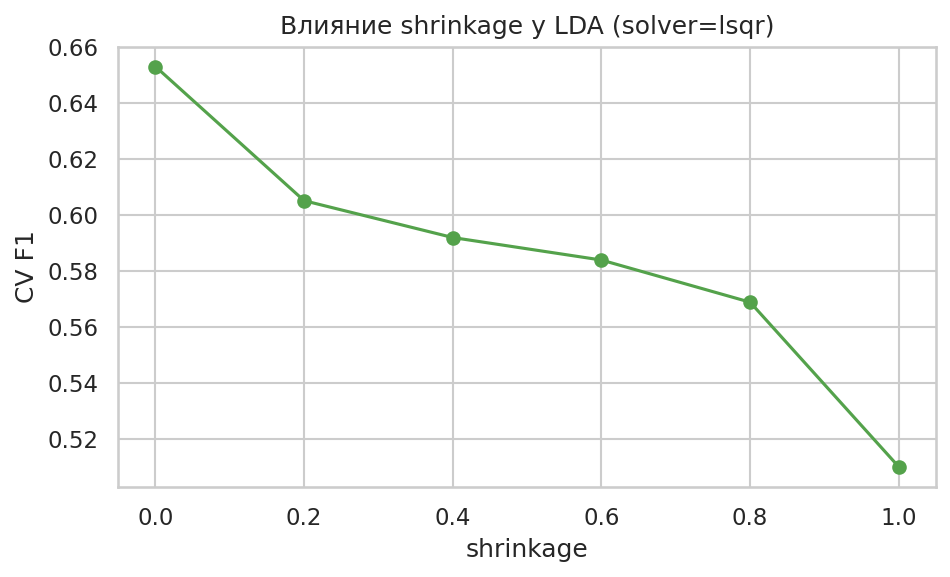

,Accuracy,Precision,Recall,F1,AUC_ROC,Параметр
Модель,,,,,,
LDA,0.701,0.591,0.481,0.531,0.813,"solver=svd, shrinkage=None"


In [8]:
shrinkage_grid = np.linspace(0, 1, 6)
shrinkage_scores = []
for shrinkage in shrinkage_grid:
    search = GridSearchCV(
        LinearDiscriminantAnalysis(solver="lsqr", shrinkage=float(shrinkage)),
        {"solver": ["lsqr"]},
        scoring="f1",
        cv=cv,
    )
    search.fit(x_train, y_train)
    shrinkage_scores.append(search.best_score_)

lda_candidates = []
for solver, shrinkage in (("svd", None), ("lsqr", 0.0), ("lsqr", 0.2), ("lsqr", 0.5), ("lsqr", 0.8), ("lsqr", 1.0)):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis(solver=solver, shrinkage=shrinkage)),
    ])
    fold_scores = []
    for train_index, valid_index in cv.split(x_train, y_train):
        fold_model = clone(model)
        fold_model.fit(x_train.iloc[train_index], y_train.iloc[train_index])
        prediction = fold_model.predict(x_train.iloc[valid_index])
        fold_scores.append(f1_score(y_train.iloc[valid_index], prediction))
    lda_candidates.append({"solver": solver, "shrinkage": shrinkage, "CV F1": float(np.mean(fold_scores)), "model": model})

lda_best = max(lda_candidates, key=lambda item: item["CV F1"])
lda_best["model"].fit(x_train, y_train)
lda_row, lda_score = evaluate_model("LDA", lda_best["model"], x_test, y_test)
lda_row["Параметр"] = f"solver={lda_best['solver']}, shrinkage={lda_best['shrinkage']}"
results.append({key: value for key, value in lda_row.items() if key != "Параметр"})
test_scores["LDA"] = lda_score

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(shrinkage_grid, shrinkage_scores, marker="o", color="#54A24B")
ax.set_xlabel("shrinkage")
ax.set_ylabel("CV F1")
ax.set_title("Влияние shrinkage у LDA (solver=lsqr)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_lda_shrinkage.png", bbox_inches="tight")
plt.show()
display(pd.DataFrame([lda_row]).set_index("Модель").round(3))


### Пояснение к линейному дискриминантному анализу

- **Идея метода.** LDA ищет линейную проекцию, которая лучше всего разделяет классы, и относит пациентку к классу с большей апостериорной вероятностью. Параметр `shrinkage` сжимает оценку ковариационной матрицы, если признаки коррелируют.
- **Настройка.** Сравнены solver `svd` без сжатия и solver `lsqr` при shrinkage от 0 до 1. На графике без стандартизации CV F1 падает примерно на 0,143: инсулин и родословная имеют разный масштаб, и сжатие ковариации это проявляет. В итоговой модели признаки сначала стандартизуются, и там shrinkage почти не улучшает CV F1.
- **Выбранные параметры:** solver=svd, shrinkage=None. На тесте Accuracy = 0,701, Precision = 0,591, Recall = 0,481, F1 = 0,531, AUC-ROC = 0,813.


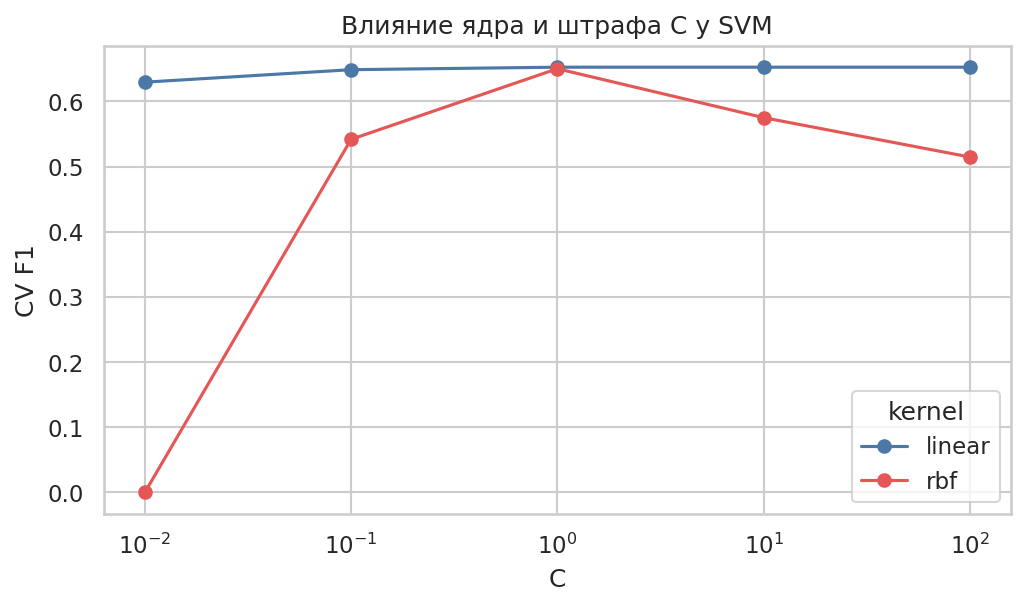

kernel,linear,rbf
C,,
0.01,0.629,0.000
0.10,0.649,0.542
1.00,0.652,0.650
10.00,0.652,0.575
100.00,0.652,0.515


,Accuracy,Precision,Recall,F1,AUC_ROC,Параметр
Модель,,,,,,
SVM,0.701,0.591,0.481,0.531,0.814,"kernel=linear, C=10.0"


In [9]:
c_grid = np.logspace(-2, 2, 5)
svm_rows = []
for kernel in ("linear", "rbf"):
    for c_value in c_grid:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(kernel=kernel, C=float(c_value), random_state=RANDOM_STATE)),
        ])
        fold_scores = []
        for train_index, valid_index in cv.split(x_train, y_train):
            fold_model = clone(model)
            fold_model.fit(x_train.iloc[train_index], y_train.iloc[train_index])
            prediction = fold_model.predict(x_train.iloc[valid_index])
            fold_scores.append(f1_score(y_train.iloc[valid_index], prediction))
        svm_rows.append({"kernel": kernel, "C": float(c_value), "CV F1": float(np.mean(fold_scores))})

svm_table = pd.DataFrame(svm_rows)
best_svm = svm_table.sort_values("CV F1", ascending=False).iloc[0]
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel=best_svm["kernel"], C=float(best_svm["C"]), random_state=RANDOM_STATE)),
])
svm_model.fit(x_train, y_train)
svm_row, svm_score = evaluate_model("SVM", svm_model, x_test, y_test)
svm_row["Параметр"] = f"kernel={best_svm['kernel']}, C={best_svm['C']}"
results.append({key: value for key, value in svm_row.items() if key != "Параметр"})
test_scores["SVM"] = svm_score

fig, ax = plt.subplots(figsize=(7, 4.2))
for kernel, color in (("linear", "#4C78A8"), ("rbf", "#E45756")):
    part = svm_table[svm_table["kernel"] == kernel]
    ax.plot(part["C"], part["CV F1"], marker="o", color=color, label=kernel)
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("CV F1")
ax.set_title("Влияние ядра и штрафа C у SVM")
ax.legend(title="kernel")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_svm_c.png", bbox_inches="tight")
plt.show()
display(svm_table.pivot(index="C", columns="kernel", values="CV F1").round(3))
display(pd.DataFrame([svm_row]).set_index("Модель").round(3))


### Пояснение к методу опорных векторов

- **Идея метода.** SVM проводит границу с максимальным зазором. Параметр `C` задаёт штраф за ошибки: малое `C` делает границу более гладкой, большое — подгоняет её к обучающим точкам. Ядро `linear` строит линейную границу, `rbf` — нелинейную.
- **Настройка.** Для обоих ядер перебраны значения `C` от 0,01 до 100. Перед обучением признаки стандартизованы, потому что штраф зависит от масштаба.
- **Выбранные параметры:** kernel=linear, C=10.0. На тесте Accuracy = 0,701, Precision = 0,591, Recall = 0,481, F1 = 0,531, AUC-ROC = 0,814.
- **Влияние C.** На графике видно, как качество каждого ядра меняется вместе со штрафом. Слишком маленький `C` недоучивает границу, а слишком большой начинает подстраиваться под обучающие строки.


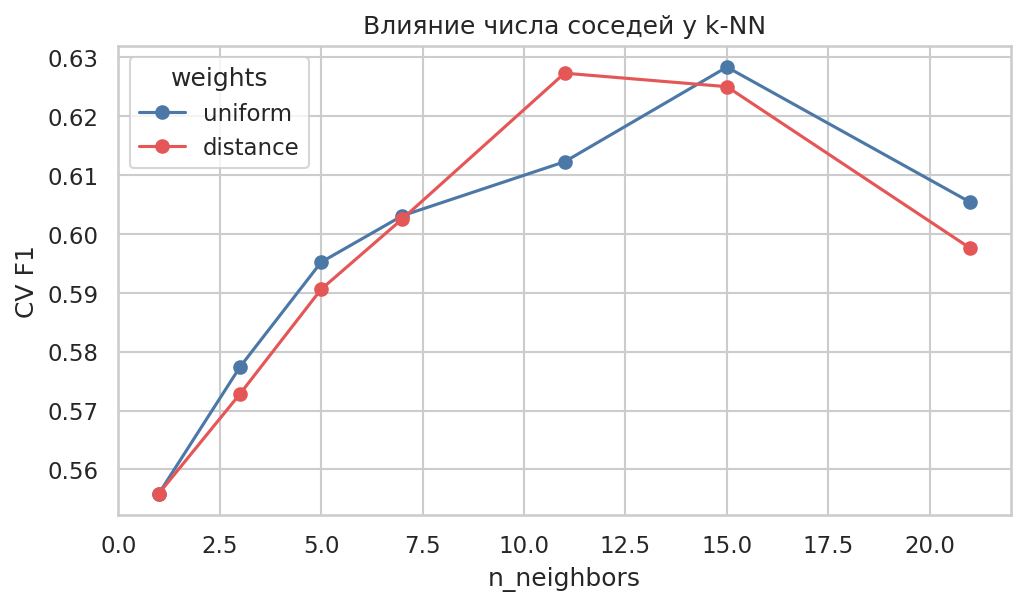

weights,distance,uniform
n_neighbors,,
1,0.556,0.556
3,0.573,0.577
5,0.591,0.595
7,0.603,0.603
11,0.627,0.612
15,0.625,0.628
21,0.598,0.605


,Accuracy,Precision,Recall,F1,AUC_ROC,Параметр
Модель,,,,,,
k-NN,0.74,0.652,0.556,0.6,0.807,"n_neighbors=15, weights=uniform"


In [10]:
neighbor_grid = [1, 3, 5, 7, 11, 15, 21]
knn_rows = []
for n_neighbors in neighbor_grid:
    for weights in ("uniform", "distance"):
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights)),
        ])
        fold_scores = []
        for train_index, valid_index in cv.split(x_train, y_train):
            fold_model = clone(model)
            fold_model.fit(x_train.iloc[train_index], y_train.iloc[train_index])
            prediction = fold_model.predict(x_train.iloc[valid_index])
            fold_scores.append(f1_score(y_train.iloc[valid_index], prediction))
        knn_rows.append({"n_neighbors": n_neighbors, "weights": weights, "CV F1": float(np.mean(fold_scores))})

knn_table = pd.DataFrame(knn_rows)
best_knn = knn_table.sort_values("CV F1", ascending=False).iloc[0]
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=int(best_knn["n_neighbors"]), weights=best_knn["weights"])),
])
knn_model.fit(x_train, y_train)
knn_row, knn_score = evaluate_model("k-NN", knn_model, x_test, y_test)
knn_row["Параметр"] = f"n_neighbors={int(best_knn['n_neighbors'])}, weights={best_knn['weights']}"
results.append({key: value for key, value in knn_row.items() if key != "Параметр"})
test_scores["k-NN"] = knn_score

fig, ax = plt.subplots(figsize=(7, 4.2))
for weights, color in (("uniform", "#4C78A8"), ("distance", "#E45756")):
    part = knn_table[knn_table["weights"] == weights]
    ax.plot(part["n_neighbors"], part["CV F1"], marker="o", color=color, label=weights)
ax.set_xlabel("n_neighbors")
ax.set_ylabel("CV F1")
ax.set_title("Влияние числа соседей у k-NN")
ax.legend(title="weights")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07b_knn_k.png", bbox_inches="tight")
plt.show()
display(knn_table.pivot(index="n_neighbors", columns="weights", values="CV F1").round(3))
display(pd.DataFrame([knn_row]).set_index("Модель").round(3))


### Пояснение к методу ближайших соседей

- **Идея метода.** Новый объект получает класс большинства среди k ближайших обучающих объектов. Признаки сначала стандартизуются, иначе признак с большим масштабом перетягивает расстояние.
- **Настройка.** Перебраны k из множества 1, 3, 5, 7, 11, 15 и 21 и веса `uniform` и `distance`. Критерий выбора — средний F1 на кросс-валидации.
- **Выбранные параметры:** n_neighbors=15, weights=uniform. На тесте Accuracy = 0,740, Precision = 0,652, Recall = 0,556, F1 = 0,600, AUC-ROC = 0,807.
- **Влияние k.** Размах CV F1 по сетке равен 0,072: слишком маленький k подстраивается под отдельных соседей, а слишком большой сглаживает границу в сторону частого класса.


,Accuracy,Precision,Recall,F1,AUC_ROC,CV F1
Модель,,,,,,
GaussianNB,0.701,0.567,0.630,0.596,0.765,0.637
MultinomialNB,0.623,0.447,0.315,0.370,0.615,0.433
ComplementNB,0.636,0.481,0.463,0.472,0.615,0.437
BernoulliNB,0.727,0.630,0.537,0.580,0.759,0.597
Decision Tree,0.740,0.675,0.500,0.574,0.811,NaN
LDA,0.701,0.591,0.481,0.531,0.813,NaN
SVM,0.701,0.591,0.481,0.531,0.813,NaN
k-NN,0.740,0.652,0.556,0.600,0.807,NaN


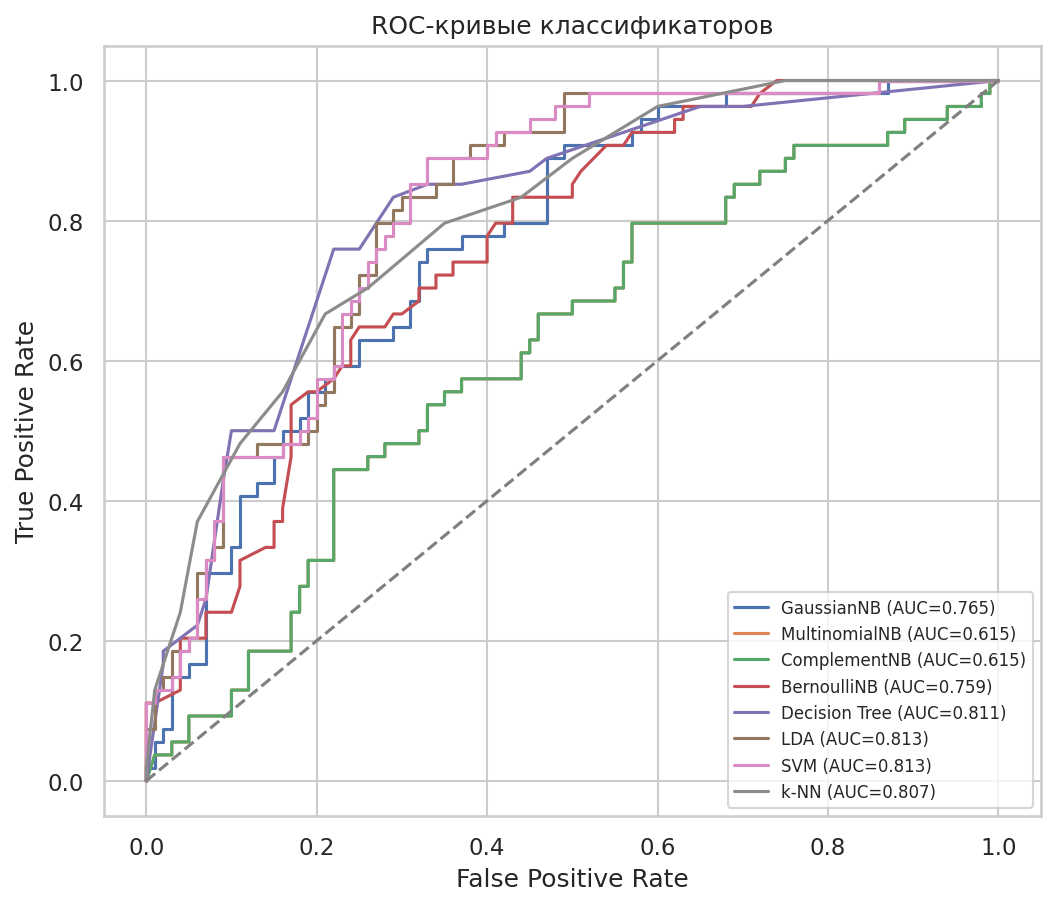

In [10]:
classical = pd.DataFrame(results).set_index("Модель")
classical.to_csv(OUTPUT_DIR / "metrics_classical.csv", encoding="utf-8-sig")
display(classical.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
for name, score in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    auc = roc_auc_score(y_test, score)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC-кривые классификаторов")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_roc_classical.png", bbox_inches="tight")
plt.show()


### Пояснение к сравнению классических моделей

- Итоговая таблица собрана по одной и той же тестовой выборке. Положительный класс — диабет, поэтому Recall показывает, какую долю больных пациенток модель не пропускает.
- Среди классических моделей по тестовому F1 лидирует **k-NN**: Accuracy = 0,740, Precision = 0,652, Recall = 0,556, F1 = 0,600, AUC-ROC = 0,807. ROC-кривые лежат над диагональю: настроенные методы отделяют классы лучше случайного угадывания.
- Минимальная Accuracy в этой таблице — 0,623. При преобладании класса «нет диабета» высокая Accuracy сама по себе не доказывает, что модель находит больных. Дальше нейросеть сравнивается по всему набору метрик.


In [11]:
scaler_nn = StandardScaler()
x_train_nn = scaler_nn.fit_transform(x_train)
x_test_nn = scaler_nn.transform(x_test)


def make_network(hidden, activation, learning_rate):
    tf.keras.backend.clear_session()
    layers = [tf.keras.layers.Input(shape=(x_train_nn.shape[1],))]
    for units in hidden:
        layers.append(tf.keras.layers.Dense(units, activation=activation))
        layers.append(tf.keras.layers.Dropout(0.2))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


def fit_network(hidden, activation, learning_rate, epochs, batch_size, log_name, validation_data=None, validation_split=None):
    model = make_network(hidden, activation, learning_rate)
    callbacks = [tf.keras.callbacks.TensorBoard(log_dir=str(TB_DIR / log_name), histogram_freq=0, write_graph=False, update_freq="epoch")]
    fit_kwargs = {"epochs": epochs, "batch_size": batch_size, "callbacks": callbacks, "verbose": 0}
    if validation_data is not None:
        fit_kwargs["validation_data"] = validation_data
    elif validation_split is not None:
        fit_kwargs["validation_split"] = validation_split
    history = model.fit(x_train_nn, y_train, **fit_kwargs)
    return model, history


baseline_model, baseline_history = fit_network((8,), "relu", 1e-3, 40, 32, "baseline_epochs", validation_split=0.2)

experiment_rows = []
for epochs in (10, 20, 40):
    model, _ = fit_network((8,), "relu", 1e-3, epochs, 32, f"epochs_{epochs}", validation_split=0.2)
    probability = model.predict(x_test_nn, verbose=0).ravel()
    prediction = (probability >= 0.5).astype(int)
    experiment_rows.append({"Эксперимент": "эпохи", "Значение": str(epochs), **classification_metrics(y_test, prediction, probability)})

for batch_size in (16, 32, 64):
    model, _ = fit_network((8,), "relu", 1e-3, 25, batch_size, f"batch_{batch_size}", validation_split=0.2)
    probability = model.predict(x_test_nn, verbose=0).ravel()
    prediction = (probability >= 0.5).astype(int)
    experiment_rows.append({"Эксперимент": "batch", "Значение": str(batch_size), **classification_metrics(y_test, prediction, probability)})

for hidden in ((8,), (32, 16), (32, 16, 8)):
    model, _ = fit_network(hidden, "relu", 1e-3, 25, 32, "arch_" + "_".join(map(str, hidden)), validation_split=0.2)
    probability = model.predict(x_test_nn, verbose=0).ravel()
    prediction = (probability >= 0.5).astype(int)
    experiment_rows.append({"Эксперимент": "архитектура", "Значение": str(hidden), **classification_metrics(y_test, prediction, probability)})

for activation in ("relu", "tanh"):
    model, _ = fit_network((8,), activation, 1e-3, 25, 32, f"activation_{activation}", validation_split=0.2)
    probability = model.predict(x_test_nn, verbose=0).ravel()
    prediction = (probability >= 0.5).astype(int)
    experiment_rows.append({"Эксперимент": "активация", "Значение": activation, **classification_metrics(y_test, prediction, probability)})

nn_experiments = pd.DataFrame(experiment_rows)
nn_experiments.to_csv(OUTPUT_DIR / "metrics_nn_experiments.csv", index=False, encoding="utf-8-sig")
display(nn_experiments.round(3))


,Эксперимент,Значение,Accuracy,Precision,Recall,F1,AUC_ROC
0,эпохи,10,0.584,0.431,0.574,0.492,0.636
1,эпохи,20,0.662,0.517,0.574,0.544,0.687
2,эпохи,40,0.695,0.566,0.556,0.561,0.788
3,batch,16,0.714,0.632,0.444,0.522,0.795
4,batch,32,0.727,0.620,0.574,0.596,0.770
5,batch,64,0.688,0.579,0.407,0.478,0.738
6,архитектура,"(8,)",0.714,0.609,0.519,0.560,0.767
7,архитектура,"(32, 16)",0.721,0.617,0.537,0.574,0.807
8,архитектура,"(32, 16, 8)",0.734,0.610,0.667,0.637,0.802
9,активация,relu,0.695,0.581,0.463,0.515,0.793


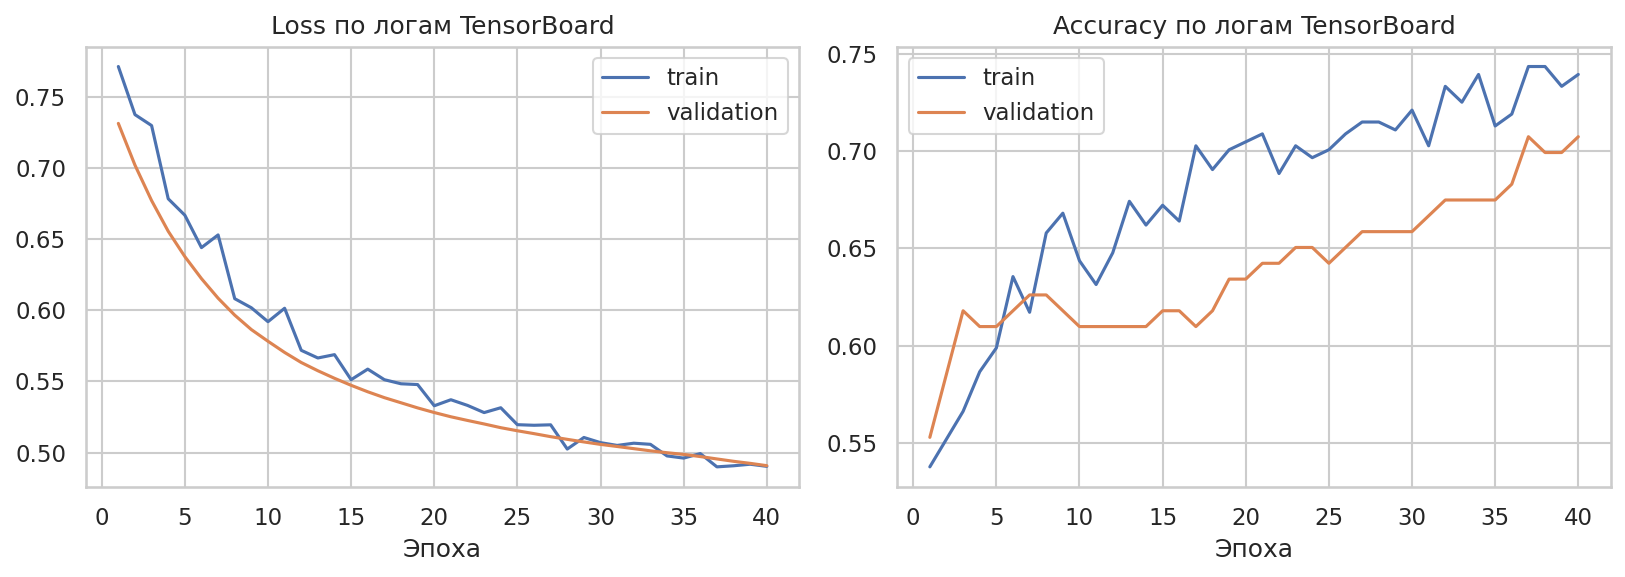

In [12]:
def read_scalar(logdir, tag_options):
    logdir = Path(logdir)
    folders = [logdir]
    if logdir.exists():
        folders.extend(path for path in logdir.rglob("*") if path.is_dir())
    for folder in folders:
        if not list(folder.glob("events.out.tfevents*")):
            continue
        accumulator = EventAccumulator(str(folder))
        accumulator.Reload()
        tags = accumulator.Tags().get("scalars", [])
        for tag in tag_options:
            if tag in tags:
                events = accumulator.Scalars(tag)
                return [event.step for event in events], [event.value for event in events]
    return [], []


train_steps, train_loss = read_scalar(TB_DIR / "baseline_epochs", ["epoch_loss"])
_, train_accuracy = read_scalar(TB_DIR / "baseline_epochs", ["epoch_accuracy"])
val_steps, val_loss = read_scalar(TB_DIR / "baseline_epochs", ["epoch_val_loss", "val_loss"])
_, val_accuracy = read_scalar(TB_DIR / "baseline_epochs", ["epoch_val_accuracy", "val_accuracy"])

if not train_steps:
    train_steps = list(range(1, len(baseline_history.history["loss"]) + 1))
    train_loss = baseline_history.history["loss"]
    train_accuracy = baseline_history.history["accuracy"]
    val_loss = baseline_history.history["val_loss"]
    val_accuracy = baseline_history.history["val_accuracy"]
    val_steps = train_steps

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(train_steps, train_loss, label="train")
if val_steps:
    axes[0].plot(val_steps, val_loss, label="validation")
axes[0].set_title("Loss по логам TensorBoard")
axes[0].set_xlabel("Эпоха")
axes[0].legend()
axes[1].plot(train_steps, train_accuracy, label="train")
if val_steps:
    axes[1].plot(val_steps, val_accuracy, label="validation")
axes[1].set_title("Accuracy по логам TensorBoard")
axes[1].set_xlabel("Эпоха")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "09_tensorboard_curves.png", bbox_inches="tight")
plt.show()


### Пояснение к нейронной сети и TensorBoard

- **Архитектура базовой сети.** Полносвязная сеть: вход из 8 стандартизованных признаков, скрытый слой на 8 нейронов с ReLU, Dropout 0,2 и выходной нейрон с сигмоидой. Функция потерь — бинарная кросс-энтропия, оптимизатор — Adam со скоростью обучения 0,001.
- **Эксперименты.** Отдельно менялись число эпох (10, 20, 40), размер батча (16, 32, 64), глубина сети и функция активации скрытого слоя (ReLU или tanh). Каждое обучение писало логи TensorBoard в `output/tensorboard`.
- **Кривые.** График loss и accuracy прочитан из логов TensorBoard базового запуска на 40 эпох. Кривые обучения и проверки показывают, выходит ли сеть на плато и расходится ли проверка с обучением.
- **Эффект параметров.** Число эпох заметно меняет качество: за 10 эпох тестовый F1 равен 0,492, за 40 эпох — 0,561. Из размеров батча лучший F1 у 32. Сеть `(32, 16, 8)` на коротком прогоне выглядит сильнее слоя из 8 нейронов. В итоговое сравнение входит базовая сеть, для которой построены кривые TensorBoard: 8 нейронов, 40 эпох и батч 32.


,Accuracy,Precision,Recall,F1,AUC_ROC
Модель,,,,,
GaussianNB,0.701,0.567,0.630,0.596,0.765
MultinomialNB,0.623,0.447,0.315,0.370,0.615
ComplementNB,0.636,0.481,0.463,0.472,0.615
BernoulliNB,0.727,0.630,0.537,0.580,0.759
Decision Tree,0.740,0.675,0.500,0.574,0.811
LDA,0.701,0.591,0.481,0.531,0.813
SVM,0.701,0.591,0.481,0.531,0.813
k-NN,0.740,0.652,0.556,0.600,0.807
Нейросеть,0.701,0.583,0.519,0.549,0.755


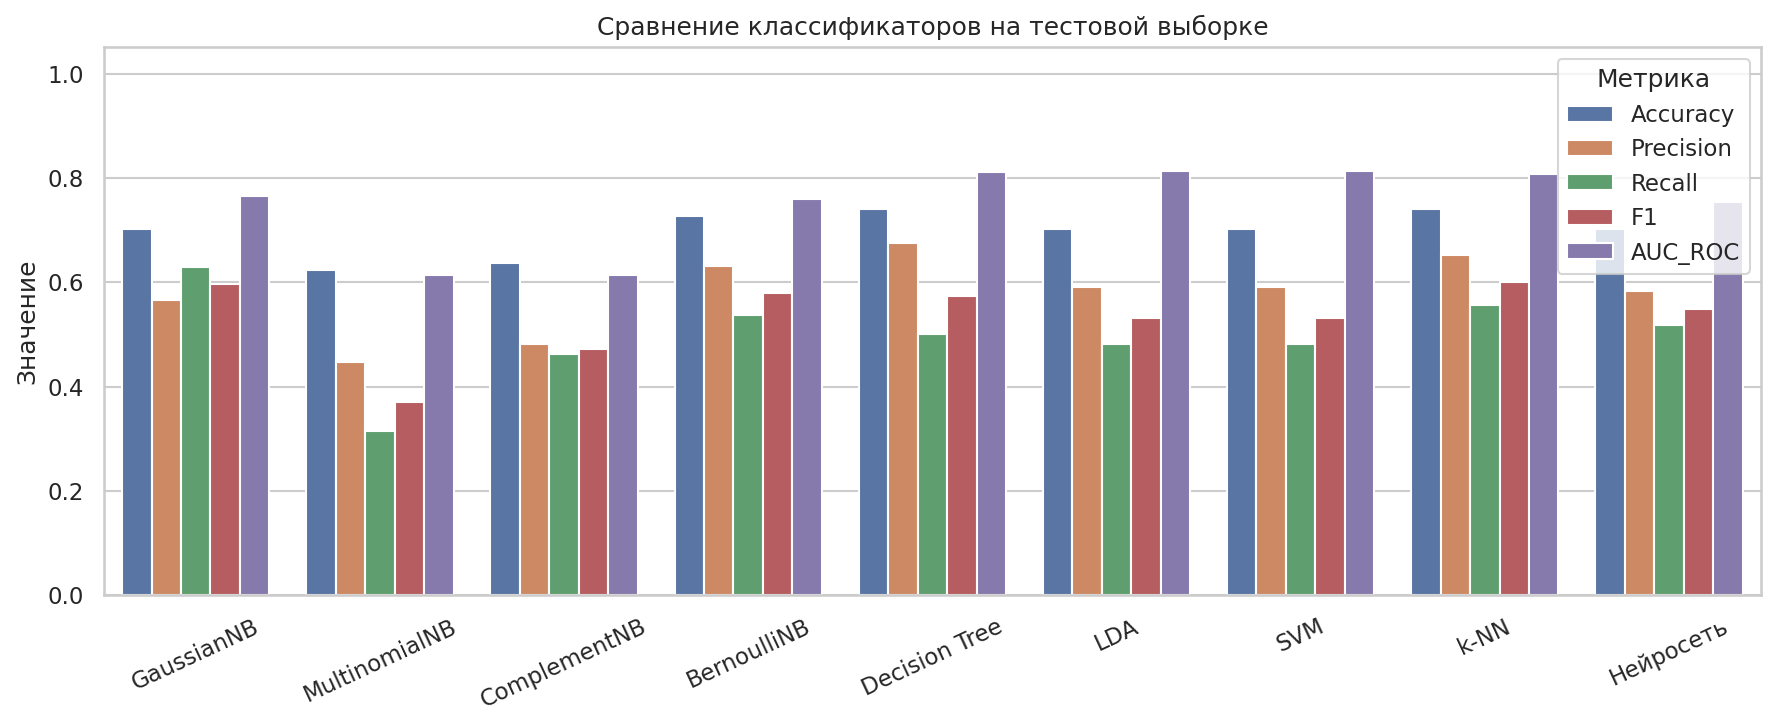

In [14]:

nn_model, _ = fit_network((8,), "relu", 1e-3, 40, 32, "final_network", validation_split=0.2)
nn_probability = nn_model.predict(x_test_nn, verbose=0).ravel()
nn_prediction = (nn_probability >= 0.5).astype(int)
nn_row = {"Модель": "Нейросеть", **classification_metrics(y_test, nn_prediction, nn_probability)}
results.append(nn_row)
test_scores["Нейросеть"] = nn_probability

final_table = pd.DataFrame(results).set_index("Модель")
final_table = final_table.drop(columns=["CV F1"], errors="ignore")
final_table.to_csv(OUTPUT_DIR / "metrics_all.csv", encoding="utf-8-sig")
display(final_table.round(3))

plot_metrics = final_table.reset_index().melt(id_vars="Модель", value_vars=["Accuracy", "Precision", "Recall", "F1", "AUC_ROC"], var_name="Метрика", value_name="Значение")
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=plot_metrics, x="Модель", y="Значение", hue="Метрика", ax=ax)
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=25)
ax.set_ylim(0, 1.05)
ax.set_title("Сравнение классификаторов на тестовой выборке")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "11_final_comparison.png", bbox_inches="tight")
plt.show()


---
## Сравнительный анализ

На одной тестовой выборке лучше всего по F1 выглядит **k-NN**: Accuracy = 0,740, Precision = 0,652, Recall = 0,556, F1 = 0,600, AUC-ROC = 0,807.

Лучшая классическая модель по F1 — **k-NN**: Accuracy = 0,740, Precision = 0,652, Recall = 0,556, F1 = 0,600, AUC-ROC = 0,807. Базовая нейросеть (8 нейронов, 40 эпох, батч 32) даёт Accuracy = 0,701, Precision = 0,583, Recall = 0,519, F1 = 0,549, AUC-ROC = 0,755. Самый высокий AUC-ROC у **SVM** (0,813). Дерево даёт Accuracy 0,740 при Recall 0,500. Признаков немного, и связь глюкозы, массы тела и возраста с диагнозом уже описывается простыми моделями.

Recall здесь важнее точности «вообще»: пропуск диабета дороже лишней проверки здоровой пациентки. Поэтому модель с чуть меньшей Accuracy, но более высоким Recall, предпочтительнее, если разница F1 невелика. В полученной таблице этот компромисс уже учтён через F1 и AUC-ROC.

## Заключение

1. **Данные.** Использован набор Pima Indians Diabetes Database с Kaggle: 768 наблюдений, положительный класс — диабет, таких случаев 268. Нули в пяти измерениях заменены медианой обучающей выборки.
2. **Признаки.** Сильнее всего с диагнозом связан признак «Глюкоза» (корреляция 0,49).
3. **Байесовские модели.** Лучший вариант на тесте — GaussianNB (F1 = 0,596). MultinomialNB и ComplementNB работают с величинами разного масштаба, поэтому уступают модели на стандартизованных или бинарных признаках.
4. **Дерево, LDA, SVM и k-NN.** Глубокое дерево запоминает обучающую выборку. Выбраны max_depth=6 и min_samples_leaf=10. У LDA выбран solver=svd. У SVM выбраны kernel=linear и C=10. Для k-NN выбраны n_neighbors=15, weights=uniform, тестовый F1 = 0,600.
5. **Нейросеть.** Сеть TensorFlow: 8 нейронов с ReLU, Dropout 0,2, сигмоида, бинарная кросс-энтропия и Adam со скоростью 0,001. Обучение на 40 эпохах записано в TensorBoard. Отдельно проверены число эпох, размер батча, глубина и функция активации.
6. **Итог.** По F1 впереди k-NN (F1 = 0,600), по AUC-ROC — SVM. Базовая нейросеть стоит рядом с простыми методами и не заменяет их на этой таблице.

---
## Список использованных источников

1. Pima Indians Diabetes Database // Kaggle. URL: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database
2. Smith J. W., Everhart J. E., Dickson W. C., Knowler W. C., Johannes R. S. Using the ADAP learning algorithm to forecast the onset of diabetes mellitus // Proceedings of the Symposium on Computer Applications and Medical Care. 1988.
3. *Hastie T., Tibshirani R., Friedman J.* The Elements of Statistical Learning. 2nd ed. Springer, 2009.
4. Документация scikit-learn: Naive Bayes, Decision Trees, LDA, SVM, k-NN. URL: https://scikit-learn.org/stable/supervised_learning.html
5. Документация TensorFlow Keras: https://www.tensorflow.org/guide/keras
6. Документация TensorBoard: https://www.tensorflow.org/tensorboard
